# Model Loading
list of models tested + one-line results:
- minicpm-v4.6:1b (response is very weird, but somewhat consistent?)
- openbmb/minicpm-v4.7:1b (inconsistent but not entirely wrong)
- openbmb/minicpm-v4.7:35b-a3b (download itself took longer than qwen3.8:27b, wont try)
- qwen3-vl:8b (thinks/reasons for too long to give sometimes inaccurate answers)
- qwen3.8:27b (took 28 mins to run, bad)
- llava:7b (miscounted workers in some images & got ppe wrong sometimes)
- gemma3:4b  (miscounted workers in some images & got ppe wrong sometimes)

run python -m pip install ollama before running below cells (first time only)

## Dependencies/Libraries

In [ ]:
from ollama import chat
import time
from pathlib import Path
from IPython.display import display, Image

In [12]:
# list contains only models that are fast (<20min) for evaluation
models = [
    "minicpm-v4.6:1b", # 0
    "openbmb/minicpm-v4.7:1b", # 1
    "qwen3-vl:8b", # 2
    "llava:7b", # 3
    "gemma3:4b" # 4
]

# Select the model you want to evaluate
modelchoice = models[1]

print(f"Selected model: {modelchoice}")

Selected model: openbmb/minicpm-v4.7:1b


# Evaluation

Found 6 images


Analysing: 004063_jpg.rf.6ecc587c20a87ec176841aea39b8f5db.jpg


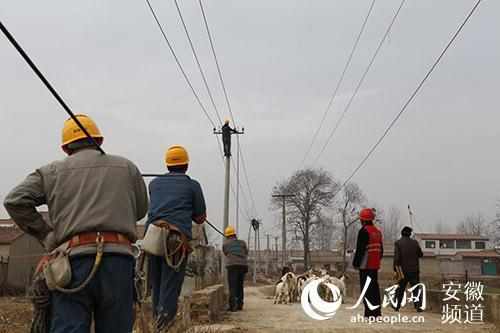

To analyze PPE compliance for the image:  

### 1. Identify Visible Workers  
There are 5 visible workers:  
- Worker 1 (left foreground, yellow helmet, gray jacket)  
- Worker 2 (middle left, yellow helmet, blue shirt)  
- Worker 3 (center background, yellow helmet)  
- Worker 4 (right middle, red helmet, red vest)  
- Worker 5 (far right, brown coat, no helmet)  


### 2. PPE Details (Helmet, Vest, Boots)  
- **Helmet**: Worn by Workers 1, 2, 3, 4. Worker 5 has no helmet.  
- **Safety Vest**: Worn by Workers 2, 4. Workers 1, 3, 5 lack vests.  
- **Safety Boots**: All workers likely have boots (harnesses/footwear visible).  


### 3. PPE Compliance Summary  
- Total workers: 5  
- Workers with missing PPE:  
  - Helmet: Worker 5 (far right) is missing.  
  - Safety vest: Workers 1, 3, 5 lack vests.  
  - Safety boots: No missing (all present).  
- Overall violation: Yes (missing helmets/vests for some workers).  


Total workers: 5  
Workers with missing PPE: 3 (missing helmet, safety

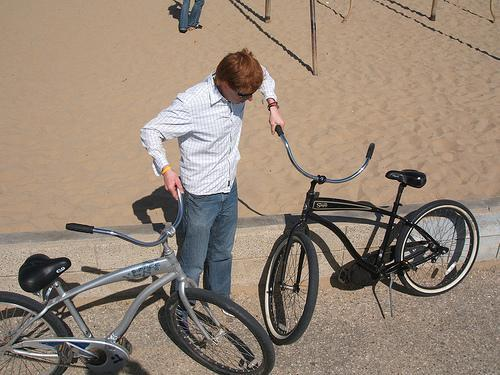

To analyze PPE compliance for the image:  

1. **Identify visible workers**:  
   - Worker 1: Center, wearing striped shirt, jeans, and a white safety vest, holding bicycle handlebars.  
   - Worker 2: Background (legs visible, possibly near the fence).  

2. **PPE details**:  
   - Helmet: Missing (no helmet visible; the main worker’s head has no helmet).  
   - Safety vest: Worn (white safety vest is present).  
   - Safety boots: Missing (no safety boots visible; worker is in jeans).  

3. **Total workers**: 2  
4. Workers with missing PPE:  
   - Helmet (missing)  
   - Safety boots (missing)  
5. Overall violation: Yes (missing helmet and safety boots are clear PPE gaps).  


Total workers: 2  
Workers with missing PPE: 2 (helmet, safety boots)  
Overall violation: Yes
Processing time: 4.13 seconds

Analysing: 2009_000059_jpg.rf.fdadf92b3365ec373f467210a8e174d5.jpg


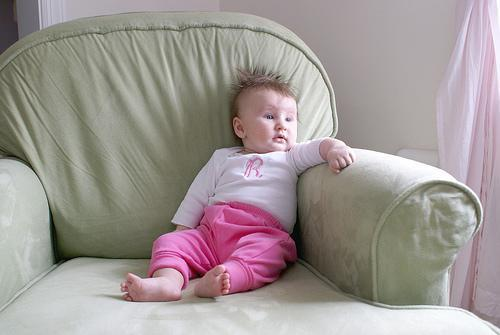

To analyze the image for PPE compliance:  
- Visible workers: There are no workers in the image; it features a baby on a chair.  
- Helmet: Not applicable (no workers are present).  
- Safety vest: Not applicable (no workers are present).  
- Safety boots: Not applicable (no workers are present).  

Total workers: 0  
Workers with missing PPE: 0  
Overall violation: No  


Total workers: 0  
Workers with missing PPE: 0  
Overall violation: No
Processing time: 2.66 seconds

Analysing: ppe_ob.jpg


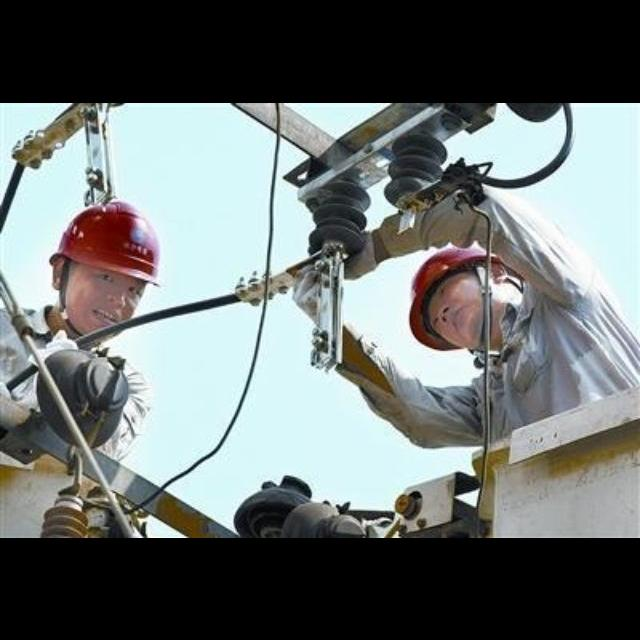

To analyze PPE compliance:  
- **Workers identified**: 2  
  - Left worker: Wears red helmet, safety vest, and safety boots (PPE present).  
  - Right worker: Wears red helmet, safety vest, and safety boots (PPE present).  

- Helmet: Worn (both workers have helmets).  
- Safety vest: Worn (both workers have vests).  
- Safety boots: Worn (both workers have safety boots).  

No PPE is missing; all PPE is present.  
- Total workers: 2  
- Workers with missing PPE: 0  
- Overall violation: No  


Total workers: 2  
Workers with missing PPE: 0  
Overall violation: No
Processing time: 2.41 seconds

Analysing: ppe_v.jpg


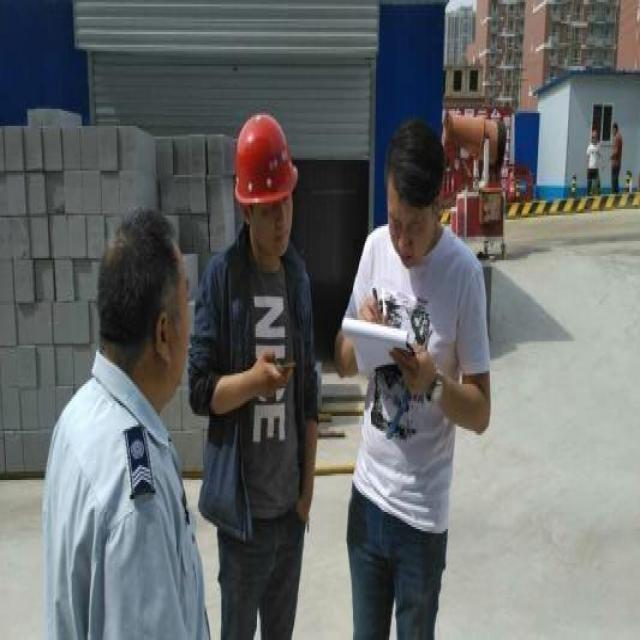

To analyze PPE compliance:  
- Visible workers: 4 (left officer, red - helmeted worker, white - t - shirt worker, background person).  

- Helmet: Worn (red helmet worn by middle worker).  
- Safety vest: Unclear (no safety vest visible; attire is a jacket, not a safety vest).  
- Safety boots: Unclear (no safety boots; workers are in jeans, so boots are missing/unclear).  

- Total workers: 4  
- Workers with missing PPE: 2 (safety vest and safety boots are unclear/missing).  
- Overall violation: Yes  


Total workers: 4  
Workers with missing PPE: 2  
Overall violation: Yes
Processing time: 3.77 seconds

Analysing: stock1.jpg


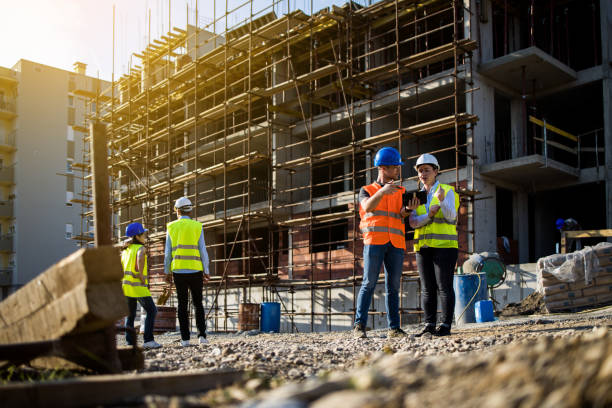

To analyze PPE compliance:  

1. **Identify visible workers**:  
   - Four construction workers are present.  
   - Position: All are workers in the construction site.  

2. **Helmet, safety vest, safety boots**:  
   - Helmet: Worn (all four have a blue/white/orange hard hat).  
   - Safety vest: Worn (all wear high-visibility yellow/orange vests).  
   - Safety boots: Missing (all workers wear jeans, no safety boots visible).  

3. **PPE compliance details**:  
   - Total workers: 4  
   - Workers with missing PPE: 4 (all have missing safety boots).  
   - Overall violation: Yes (safety boots are a critical missing PPE item).  


Total workers: 4  
Workers with missing PPE: 4  
Overall violation: Yes
Processing time: 5.37 seconds

All images processed!

Model: openbmb/minicpm-v4.7:1b
Total images analysed: 6
Total processing time: 31.57 seconds
Average processing time: 5.26 seconds
Total time: 0.53 minutes


In [ ]:
# Folder containing your PPE test images
image_folder = Path(
    r"C:\Users\GYS\Downloads\test model\model testing images"
)

# Find all JPG, JPEG and PNG images
image_paths = sorted(
    file for file in image_folder.iterdir()
    if file.suffix.lower() in [".jpg", ".jpeg", ".png"]
)

print(f"Found {len(image_paths)} images\n")
results = []
total_processing_time = 0

# Process images one at a time
for image_path in image_paths:

    print(f"\nAnalysing: {image_path.name}")
    display(Image(filename=str(image_path), width=400))

    start = time.perf_counter()

    try:
        response = chat(
            model=modelchoice,
            messages=[
                {
                "role": "user",
                "content": """
                Analyse the image for PPE compliance.

                Identify each visible worker and report:
                - Position in image
                - Helmet: Worn / Missing / Unclear
                - Safety vest: Worn / Missing / Unclear
                - Safety boots: Worn / Missing / Unclear

                Mark PPE as Missing only when its absence is
                clearly visible. If obstructed or uncertain,
                mark Unclear. Do not guess.

                Finally, report:
                - Total workers
                - Workers with missing PPE
                - Overall violation: Yes / No / Unclear
                """,
                "images": [str(image_path)]
                }
            ]
        )

        prediction = response.message.content

    except Exception as error:
        prediction = f"ERROR: {error}"

    elapsed = time.perf_counter() - start

    print(prediction)
    print(f"Processing time: {elapsed:.2f} seconds")

    results.append({
        "image": image_path.name,
        "prediction": prediction,
        "processing_time": elapsed
    })

    total_processing_time += elapsed

print("\nAll images processed!")

# NEW: Print total and average processing time
print(f"\nModel: {modelchoice}")
print(f"Total images analysed: {len(image_paths)}")
print(f"Total processing time: {total_processing_time:.2f} seconds")

if image_paths:
    average_time = total_processing_time / len(image_paths)
    print(f"Average processing time: {average_time:.2f} seconds")

print(f"Total time: {total_processing_time / 60:.2f} minutes")